# K-Nearest Neighbors (K-NN)

![](images\knn2.PNG)

Need to decide to in which category the new point lies.

In the K-NN algorithm, we need to specify the number of neighbours.

![](images\knn1.PNG)


## euclidean Distance

![](images\knn3.png)

![](images\knn4.png)


As the category 1 has more neighbours than category 2 so we will assume that the new data point belongs to the 1st category.


---

## Other Types of Distance

![](images/K1.png)

![](images/K2.png)


Choosing the right distance metrics impacts the way KNN performs especially in the high-dimensional cases.


## Curse of Dimensionality

As the number of features increases, the concept of distance becomes less meaningful making it difficult for KNN to find relevant neighbors. So this requires  techniques like Dimensionality reduction.

## Pros
It is simple to implement, highly adaptable to new training data, and requires very few hyper-parameters

## Cons
- Scalability: Being a "lazy algorithm," it stores all training data in memory, making it less efficient as datasets grow.
- Curse of Dimensionality: Performance degrades in high-dimensional spaces where data points become sparse, making distance calculations less meaningful. 
- Overfitting: Low values of K can lead to overfitting, while higher values may smooth out predictions too much.

## Common Use cases
KNN is frequently applied in data preprocessing (missing value imputation), recommendation systems, financial forecasting (stock market/currency trends), and healthcare (gene expression analysis for disease prediction)

## Importing the libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

## Importing the dataset

In [2]:
dataset = pd.read_csv('Social_Network_Ads.csv')
X = dataset.iloc[:, :-1]
y = dataset.iloc[:, -1]

In [3]:
X.head()

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


In [4]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64

## Splitting the dataset into the Training set and Test set

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

In [6]:
X_train.head()

,Age,EstimatedSalary
250,44,39000
63,32,120000
312,38,50000
159,32,135000
283,52,21000


In [7]:
y_train.head()

250    0
63     1
312    0
159    1
283    1
Name: Purchased, dtype: int64

In [8]:
X_test.head()

,Age,EstimatedSalary
132,30,87000
309,38,50000
341,35,75000
196,30,79000
246,35,50000


In [9]:
print(y_test)

132    0
309    0
341    0
196    0
246    0
      ..
146    1
135    0
390    1
264    1
364    1
Name: Purchased, Length: 100, dtype: int64


## Feature Scaling

In [10]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [11]:
X_train

array([[ 0.58164944, -0.88670699],
       [-0.60673761,  1.46173768],
       [-0.01254409, -0.5677824 ],
       [-0.60673761,  1.89663484],
       [ 1.37390747, -1.40858358],
       [ 1.47293972,  0.99784738],
       [ 0.08648817, -0.79972756],
       [-0.01254409, -0.24885782],
       [-0.21060859, -0.5677824 ],
       [-0.21060859, -0.19087153],
       [-0.30964085, -1.29261101],
       [-0.30964085, -0.5677824 ],
       [ 0.38358493,  0.09905991],
       [ 0.8787462 , -0.59677555],
       [ 2.06713324, -1.17663843],
       [ 1.07681071, -0.13288524],
       [ 0.68068169,  1.78066227],
       [-0.70576986,  0.56295021],
       [ 0.77971394,  0.35999821],
       [ 0.8787462 , -0.53878926],
       [-1.20093113, -1.58254245],
       [ 2.1661655 ,  0.93986109],
       [-0.01254409,  1.22979253],
       [ 0.18552042,  1.08482681],
       [ 0.38358493, -0.48080297],
       [-0.30964085, -0.30684411],
       [ 0.97777845, -0.8287207 ],
       [ 0.97777845,  1.8676417 ],
       [-0.01254409,

In [15]:
print(X_test)

[[-0.80480212  0.50496393]
 [-0.01254409 -0.5677824 ]
 [-0.30964085  0.1570462 ]
 [-0.80480212  0.27301877]
 [-0.30964085 -0.5677824 ]
 [-1.10189888 -1.43757673]
 [-0.70576986 -1.58254245]
 [-0.21060859  2.15757314]
 [-1.99318916 -0.04590581]
 [ 0.8787462  -0.77073441]
 [-0.80480212 -0.59677555]
 [-1.00286662 -0.42281668]
 [-0.11157634 -0.42281668]
 [ 0.08648817  0.21503249]
 [-1.79512465  0.47597078]
 [-0.60673761  1.37475825]
 [-0.11157634  0.21503249]
 [-1.89415691  0.44697764]
 [ 1.67100423  1.75166912]
 [-0.30964085 -1.37959044]
 [-0.30964085 -0.65476184]
 [ 0.8787462   2.15757314]
 [ 0.28455268 -0.53878926]
 [ 0.8787462   1.02684052]
 [-1.49802789 -1.20563157]
 [ 1.07681071  2.07059371]
 [-1.00286662  0.50496393]
 [-0.90383437  0.30201192]
 [-0.11157634 -0.21986468]
 [-0.60673761  0.47597078]
 [-1.6960924   0.53395707]
 [-0.11157634  0.27301877]
 [ 1.86906873 -0.27785096]
 [-0.11157634 -0.48080297]
 [-1.39899564 -0.33583725]
 [-1.99318916 -0.50979612]
 [-1.59706014  0.33100506]
 

## Training the K-NN model on the Training set

In [16]:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors = 5, metric = 'minkowski', p = 2)
classifier.fit(X_train, y_train)

KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
                     metric_params=None, n_jobs=None, n_neighbors=5, p=2,
                     weights='uniform')

## Predicting a new result

In [17]:
print(classifier.predict(sc.transform([[30,87000]])))

[0]


## Predicting the Test set results

In [19]:
y_pred = classifier.predict(X_test)
# print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

## Making the Confusion Matrix

In [20]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)
accuracy_score(y_test, y_pred)

[[64  4]
 [ 3 29]]


0.93

> KNN model is computationally expensive.

## Visualising the Training set results

In [ ]:
from matplotlib.colors import ListedColormap

# Invert scaling so axes are plotted in original Age / EstimatedSalary units
X_set, y_set = sc.inverse_transform(X_train), y_train

# Build a fine grid covering the feature space (step=1) so the decision
# boundary drawn by contourf looks like a smooth curve, not a blocky mesh
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 1),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 1))

# Classify every point on the grid (re-scaling it first, since the model was
# trained on scaled data) and colour the regions red/green by predicted class
# -> this is the decision boundary/region
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())

# Overlay the actual training points, coloured by their true class,
# so we can see how well the boundary separates them
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('red', 'green'))(i), label = j)
plt.title('K-NN (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

Observe here the prediction boundary is not a straight line — unlike logistic regression or linear SVM, KNN is not restricted to a linear decision boundary.

Note: "not a straight line" by itself just means the model is non-linear, not that it is overfitting. Overfitting is about *how irregular/fragmented* the boundary is (small k chasing individual noisy points), not about curvature. See the k-comparison below.

## Visualising the Test set results

'c' argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with 'x' & 'y'.  Please use a 2-D array with a single row if you really want to specify the same RGB or RGBA value for all points.
'c' argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with 'x' & 'y'.  Please use a 2-D array with a single row if you really want to specify the same RGB or RGBA value for all points.


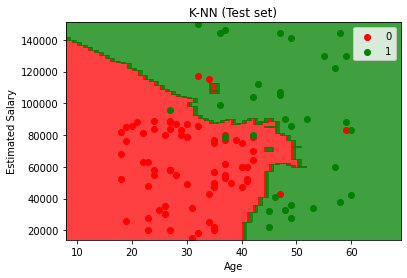

In [16]:
from matplotlib.colors import ListedColormap
X_set, y_set = sc.inverse_transform(X_test), y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 1),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 1))
plt.contourf(X1, X2, classifier.predict(sc.transform(np.array([X1.ravel(), X2.ravel()]).T)).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1], c = ListedColormap(('red', 'green'))(i), label = j)
plt.title('K-NN (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

## Effect of k on the decision boundary (bias-variance tradeoff)

Small k -> boundary fits individual training points closely (low bias, high variance, overfitting).
Large k -> boundary is smoothed over many neighbours (high bias, low variance, underfitting).

c:\Work\Github\Machine-Learning-A-Z-Udemy\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\JESWIN\AppData\Local\Temp\ipykernel_9464\838253354.py:25: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
C:\Users\JESWIN\AppData\Local\Temp\ipykernel_9464\838253354.py:25: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row i

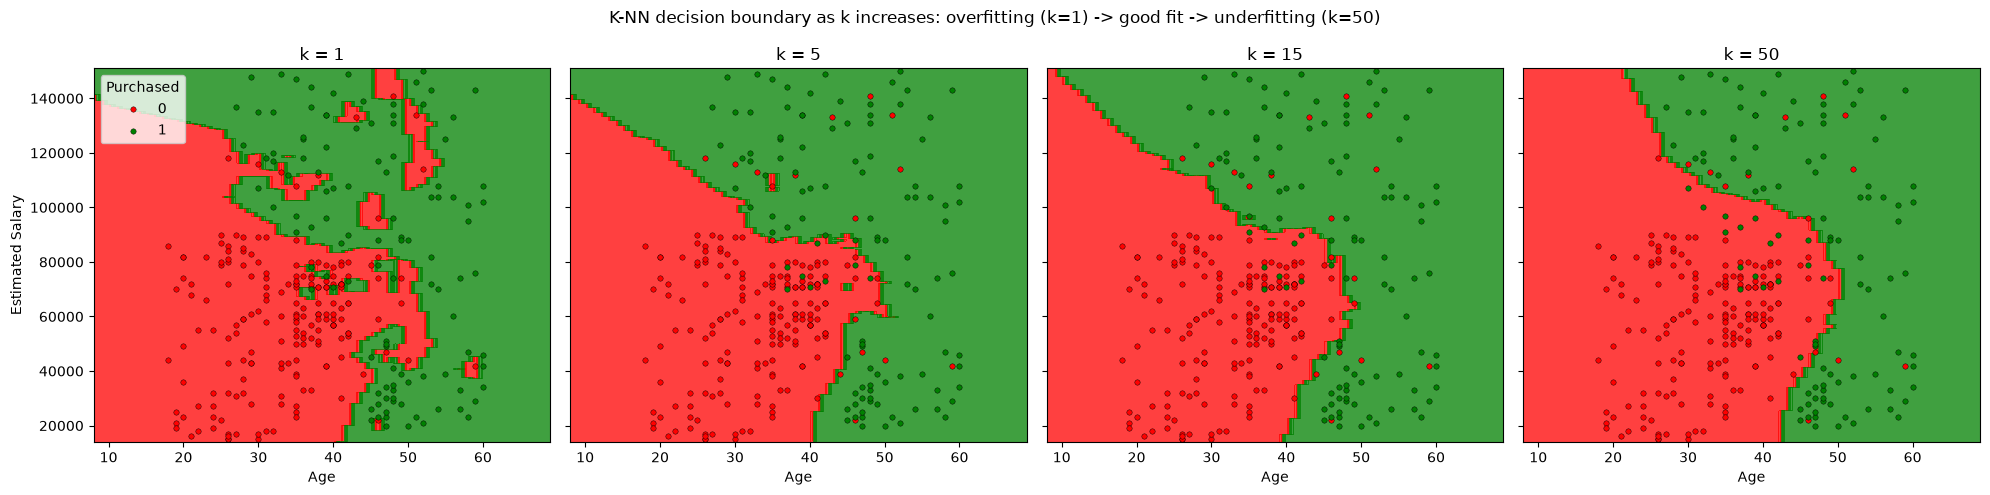

In [17]:
from matplotlib.colors import ListedColormap

# Build the grid once in original (unscaled) Age / EstimatedSalary units
X_set, y_set = sc.inverse_transform(X_train), y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 10, stop = X_set[:, 0].max() + 10, step = 1),
                     np.arange(start = X_set[:, 1].min() - 1000, stop = X_set[:, 1].max() + 1000, step = 1))
grid_points_scaled = sc.transform(np.array([X1.ravel(), X2.ravel()]).T)

k_values = [1, 5, 15, 50]

fig, axes = plt.subplots(1, len(k_values), figsize=(20, 5), sharex=True, sharey=True)

for ax, k in zip(axes, k_values):
    # Fit a fresh KNN classifier for each k on the same scaled training data
    knn_k = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=2)
    knn_k.fit(X_train, y_train)

    # Predict the class for every point on the grid -> decision regions for this k
    Z = knn_k.predict(grid_points_scaled).reshape(X1.shape)
    ax.contourf(X1, X2, Z, alpha=0.75, cmap=ListedColormap(('red', 'green')))

    # Overlay the real training points so we can see how closely the
    # boundary is hugging (or ignoring) them
    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                   c=ListedColormap(('red', 'green'))(i), s=15, edgecolor='k', linewidth=0.3, label=j)

    ax.set_title(f'k = {k}')
    ax.set_xlabel('Age')

axes[0].set_ylabel('Estimated Salary')
axes[0].legend(title='Purchased')
fig.suptitle('K-NN decision boundary as k increases: overfitting (k=1) -> good fit -> underfitting (k=50)')
plt.tight_layout()
plt.show()

## Non-straight ≠ overfitting



The note in your notebook ("the prediction boundary is not a straight line") is really just pointing out **non-linearity** — KNN can draw curved boundaries, unlike logistic regression or linear SVM which can only draw a straight line (hyperplane). That's a statement about model *flexibility*, not about overfitting.

**Overfitting is about irregularity/complexity relative to the true signal, not straightness.** A curved boundary can be:

* **Just right** — smoothly curved, tracking the real underlying pattern (e.g. k=15–20 in your data)


* **Overfit** — jagged, with little islands and peninsulas wrapping around individual noisy points (e.g. k=1)


* **Underfit** — almost straight/oversmoothed, ignoring real curvature in the data (e.g. k=100+)



So "not a straight line" alone tells you KNN *can* model non-linear relationships. What actually signals overfitting is **how wiggly/fragmented** the boundary is — specifically, whether it's chasing individual training points (very low k) rather than the general trend.

The mechanism: with `k=1`, every training point's own label becomes its own tiny neighborhood — the boundary forms little loops around single outliers. As k grows, each prediction averages over more neighbors, smoothing those loops out. Push k too far and you oversmooth past the real pattern.